<b>ML Experiment 1: Implementation of Simple Linear Regression</b><br><br><b>Aim:</b> Model delivery transit minutes from dispatch distance using analytical OLS formulas and scikit-learn LinearRegression, then inspect R2 and holdout residuals.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
def compute_ols_params(feature_vals, target_vals):
    dx = feature_vals - np.mean(feature_vals)
    dy = target_vals - np.mean(target_vals)
    beta_1 = float(np.dot(dx, dy) / np.dot(dx, dx))
    beta_0 = float(np.mean(target_vals) - beta_1 * np.mean(feature_vals))
    return beta_1, beta_0

generator = np.random.default_rng(101)
dispatch_km = np.linspace(2.5, 48.0, 68)
transit_minutes = 11.4 + 1.85 * dispatch_km + generator.normal(0.0, 4.1, size=dispatch_km.shape[0])

shipment_df = pd.DataFrame({
    "Dispatch_Km": np.round(dispatch_km, 2),
    "Transit_Minutes": np.round(np.clip(transit_minutes, 10.0, None), 2),
})

print("Delivery Dataset Snapshot:")
print(shipment_df.head(6).to_string(index=False))

km_col = shipment_df[["Dispatch_Km"]]
mins_col = shipment_df["Transit_Minutes"]

train_km, test_km, train_mins, test_mins = train_test_split(
    km_col, mins_col, test_size=0.22, random_state=17
)

slope_est, intercept_est = compute_ols_params(
    train_km["Dispatch_Km"].to_numpy(), train_mins.to_numpy()
)

ols_reg = LinearRegression()
ols_reg.fit(train_km, train_mins)

Delivery Dataset Snapshot:
 Dispatch_Km  Transit_Minutes
        2.50            12.79
        3.18            10.00
        3.86            21.01
        4.54            22.85
        5.22            19.78
        5.90            23.81


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [3]:
pred_mins = ols_reg.predict(test_km)

mse_val = mean_squared_error(test_mins, pred_mins)
rmse_val = np.sqrt(mse_val)
mae_val = mean_absolute_error(test_mins, pred_mins)
r2_val = r2_score(test_mins, pred_mins)

print(f"\nFormula OLS  -> Slope: {slope_est:.4f}, Intercept: {intercept_est:.4f}")
print(f"Sklearn OLS  -> Slope: {ols_reg.coef_[0]:.4f}, Intercept: {ols_reg.intercept_:.4f}")
print(f"Holdout MSE: {mse_val:.3f} | RMSE: {rmse_val:.3f} | MAE: {mae_val:.3f} | R2: {r2_val:.4f}")

query_df = pd.DataFrame({"Dispatch_Km": [25.0]})
print(f"Estimated Transit Time for 25 km: {ols_reg.predict(query_df)[0]:.2f} mins")

err_vals = test_mins - pred_mins
grid_km = np.linspace(shipment_df["Dispatch_Km"].min(), shipment_df["Dispatch_Km"].max(), 120)
grid_pred = ols_reg.predict(pd.DataFrame({"Dispatch_Km": grid_km}))


Formula OLS  -> Slope: 1.8684, Intercept: 10.9456
Sklearn OLS  -> Slope: 1.8684, Intercept: 10.9456
Holdout MSE: 12.269 | RMSE: 3.503 | MAE: 2.969 | R2: 0.9726
Estimated Transit Time for 25 km: 57.66 mins


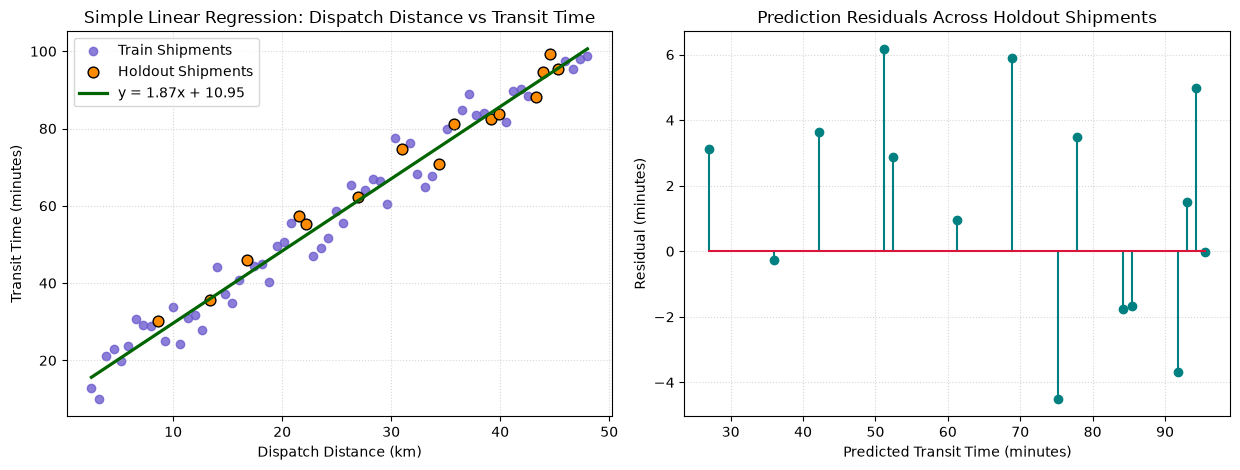

In [4]:
fig, panels = plt.subplots(1, 2, figsize=(12.5, 4.8))

panels[0].scatter(train_km, train_mins, color="slateblue", alpha=0.78, label="Train Shipments")
panels[0].scatter(test_km, test_mins, color="darkorange", edgecolor="black", s=60, label="Holdout Shipments")
panels[0].plot(
    grid_km,
    grid_pred,
    color="darkgreen",
    linewidth=2.3,
    label=f"y = {ols_reg.coef_[0]:.2f}x + {ols_reg.intercept_:.2f}",
)
panels[0].set_title("Simple Linear Regression: Dispatch Distance vs Transit Time")
panels[0].set_xlabel("Dispatch Distance (km)")
panels[0].set_ylabel("Transit Time (minutes)")
panels[0].legend()
panels[0].grid(True, linestyle=":", alpha=0.5)

panels[1].stem(pred_mins, err_vals, linefmt="teal", markerfmt="o", basefmt="crimson")
panels[1].set_title("Prediction Residuals Across Holdout Shipments")
panels[1].set_xlabel("Predicted Transit Time (minutes)")
panels[1].set_ylabel("Residual (minutes)")
panels[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> Both analytical OLS and scikit-learn produce identical slope and intercept estimates with low holdout RMSE and balanced residual spread around zero.